In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("college_student_placement_dataset.csv")

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,8,No,8,8,4,No
1,CLG0061,97,5.52,5.37,8,No,7,8,0,No
2,CLG0036,109,5.36,5.83,9,No,3,1,1,No
3,CLG0055,122,5.47,5.75,6,Yes,1,6,1,No
4,CLG0004,96,7.91,7.69,7,No,8,10,2,No


In [19]:
#Understand the dataset
# Display first five rows
display(df.head())

# Dataset shape
print("Number of rows and columns:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,8,No,8,8,4,No
1,CLG0061,97,5.52,5.37,8,No,7,8,0,No
2,CLG0036,109,5.36,5.83,9,No,3,1,1,No
3,CLG0055,122,5.47,5.75,6,Yes,1,6,1,No
4,CLG0004,96,7.91,7.69,7,No,8,10,2,No


Number of rows and columns: (10000, 10)

Column Names:
['College_ID', 'IQ', 'Prev_Sem_Result', 'CGPA', 'Academic_Performance', 'Internship_Experience', 'Extra_Curricular_Score', 'Communication_Skills', 'Projects_Completed', 'Placement']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   College_ID              10000 non-null  object 
 1   IQ                      10000 non-null  int64  
 2   Prev_Sem_Result         10000 non-null  float64
 3   CGPA                    10000 non-null  float64
 4   Academic_Performance    10000 non-null  int64  
 5   Internship_Experience   10000 non-null  object 
 6   Extra_Curricular_Score  10000 non-null  int64  
 7   Communication_Skills    10000 non-null  int64  
 8   Projects_Completed      10000 non-null  int64  
 9   Placement               10000 non-null  objec

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
count,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000,10000.000000,10000.000000,10000.000000,10000
unique,100,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN,2
top,CLG0062,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN,No
freq,133,NaN,NaN,NaN,NaN,6036,NaN,NaN,NaN,8341
mean,NaN,99.471800,7.535673,7.532379,5.546400,NaN,4.970900,5.561800,2.513400,NaN
std,NaN,15.053101,1.447519,1.470141,2.873477,NaN,3.160103,2.900866,1.715959,NaN
min,NaN,41.000000,5.000000,4.540000,1.000000,NaN,0.000000,1.000000,0.000000,NaN
25%,NaN,89.000000,6.290000,6.290000,3.000000,NaN,2.000000,3.000000,1.000000,NaN
50%,NaN,99.000000,7.560000,7.550000,6.000000,NaN,5.000000,6.000000,3.000000,NaN
75%,NaN,110.000000,8.790000,8.770000,8.000000,NaN,8.000000,8.000000,4.000000,NaN



Missing Values:
College_ID                0
IQ                        0
Prev_Sem_Result           0
CGPA                      0
Academic_Performance      0
Internship_Experience     0
Extra_Curricular_Score    0
Communication_Skills      0
Projects_Completed        0
Placement                 0
dtype: int64

Duplicate Records: 0


In [5]:
# Remove duplicate records
df = df.drop_duplicates()

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("Data cleaning completed!")
print("Updated dataset shape:", df.shape)

display(df.head())

Data cleaning completed!
Updated dataset shape: (10000, 10)


,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,8,No,8,8,4,No
1,CLG0061,97,5.52,5.37,8,No,7,8,0,No
2,CLG0036,109,5.36,5.83,9,No,3,1,1,No
3,CLG0055,122,5.47,5.75,6,Yes,1,6,1,No
4,CLG0004,96,7.91,7.69,7,No,8,10,2,No


Target column: Placement
Placement
No     8341
Yes    1659
Name: count, dtype: int64


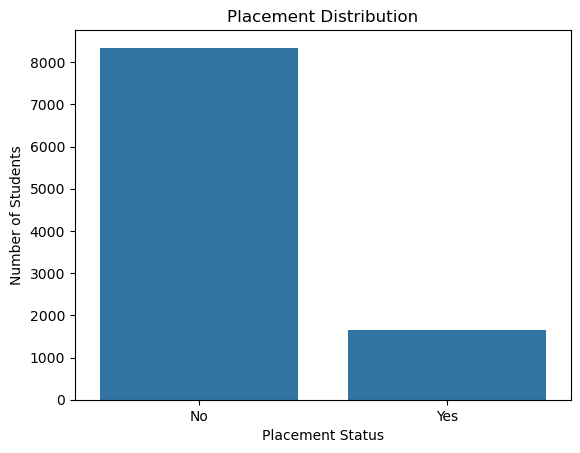

In [6]:
# Find the target column
possible_targets = [
    "PlacementStatus",
    "Placement_Status",
    "Placement",
    "Placed"
]

target_column = next(
    (col for col in possible_targets if col in df.columns),
    None
)

print("Target column:", target_column)

if target_column is None:
    print("Target column not detected. Check the column names above.")
else:
    print(df[target_column].value_counts())

    sns.countplot(data=df, x=target_column)
    plt.title("Placement Distribution")
    plt.xlabel("Placement Status")
    plt.ylabel("Number of Students")
    plt.show()

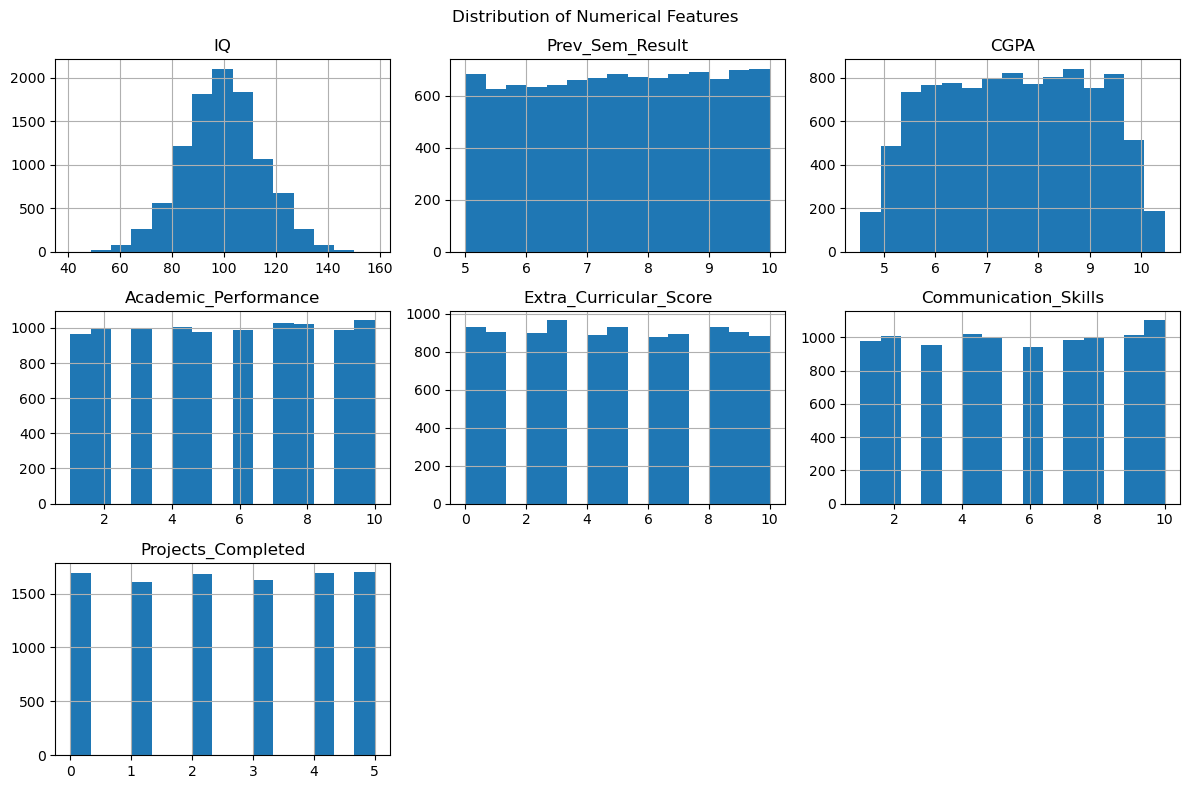

In [7]:
df.select_dtypes(include=np.number).hist(
    figsize=(12, 8),
    bins=15
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

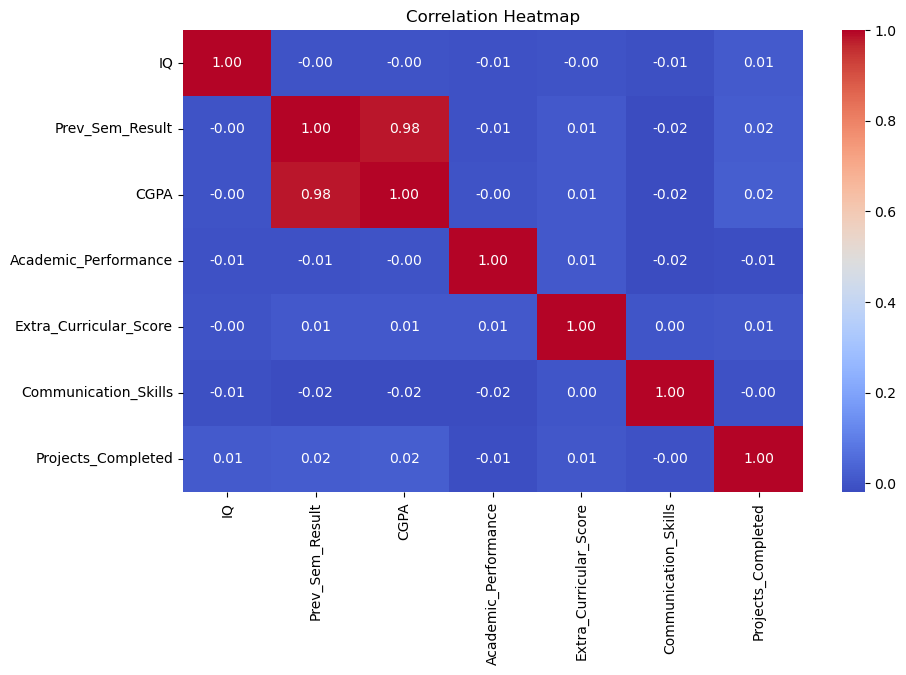

In [8]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [9]:
if target_column is None:
    raise ValueError(
        "Please identify the placement target column and set target_column manually."
    )

# Separate input features and target
X = df.drop(columns=[target_column])
y = df[target_column]

print("Input features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(target_column)

print("\nTarget values:")
print(y.value_counts())

Input features:
['College_ID', 'IQ', 'Prev_Sem_Result', 'CGPA', 'Academic_Performance', 'Internship_Experience', 'Extra_Curricular_Score', 'Communication_Skills', 'Projects_Completed']

Target variable:
Placement

Target values:
Placement
No     8341
Yes    1659
Name: count, dtype: int64


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 8000
Testing records: 2000


In [11]:
# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predict test data
    y_pred = pipeline.predict(X_test)

    # Evaluate model
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [13]:
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="Accuracy",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,1.0000,1.000000,1.0000,1.000000
1,Random Forest,0.9975,0.997507,0.9975,0.997492
2,Logistic Regression,0.8985,0.892233,0.8985,0.893318


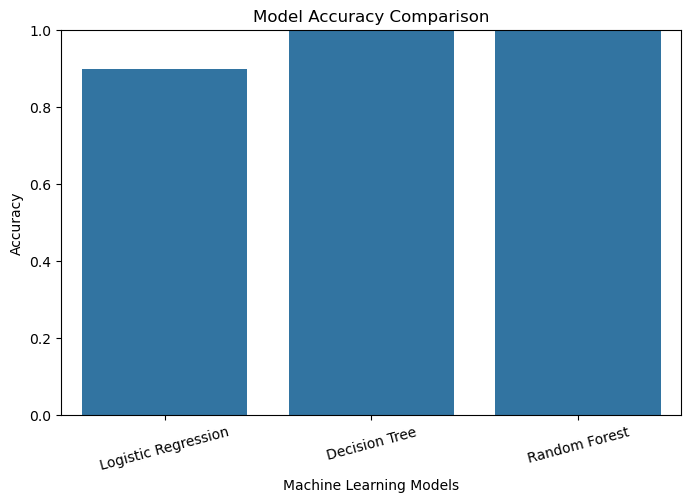

In [14]:
#Visualize model accuracy
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

In [15]:
#Select the best model
best_model_name = results_df.loc[
    results_df["Accuracy"].idxmax(),
    "Model"
]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Decision Tree


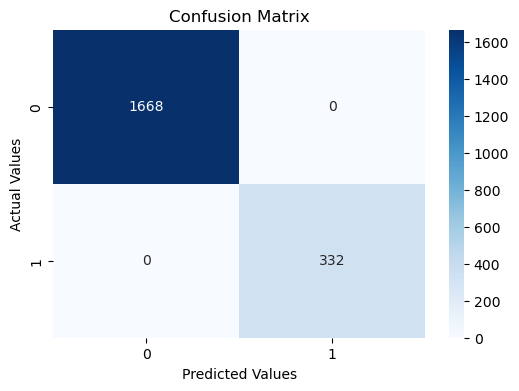

              precision    recall  f1-score   support

          No       1.00      1.00      1.00      1668
         Yes       1.00      1.00      1.00       332

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



In [16]:
#Confusion matrix
y_pred_best = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

print(classification_report(
    y_test,
    y_pred_best,
    zero_division=0
))

Predict placement for a student

In [17]:
# Take one student record
student_data = X_test.iloc[[0]]

# Predict placement
prediction = best_model.predict(student_data)

print("Student Details:")
display(student_data)

print("Predicted Placement Status:", prediction[0])

Student Details:


,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed
2208,CLG0057,95,5.11,5.59,2,No,1,3,5


Predicted Placement Status: No


In [18]:
# Example: predict using the first test student's features
# Replace this with your own input values when you know the columns.

new_student = pd.DataFrame(
    [X_test.iloc[0].to_dict()],
    columns=X.columns
)

prediction = best_model.predict(new_student)

print("Placement Prediction:", prediction[0])

Placement Prediction: No
